## Initial library and data imports

In [2]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
w_data = pd.read_csv("WT01-26 Yield Data for STT-464.csv")

## Data organizing

In [3]:
def descriptive_statistics(df: pd.DataFrame):
    df = df.describe().rename(index={"25%":"Q1", "50%":"Median", "75%":"Q3"})
    df.loc["IQR"] = df.loc["Q3"] - df.loc["Q1"]
    return df

In [4]:
w_data_width7 = w_data[w_data["WIDTH"] == 7]
w_data_width5 = w_data[w_data["WIDTH"] == 5]
yield_data_7 = w_data_width7["YIELD"]
yield_data_5 = w_data_width5["YIELD"]

## Quality control

In [5]:
# check ONLY yield data for missing values and impossible values

# check if there are NaN values in yield data
assert np.nan not in yield_data_5, "NaN values in yield data"
assert np.nan not in yield_data_7, "NaN values in yield data"

# check for impossible values (negatives)
assert not any([x < 0 for x in yield_data_5]), "Negative values in yield data"
assert not any([x < 0 for x in yield_data_7]), "Negative values in yield data"

print("No errors")

No errors


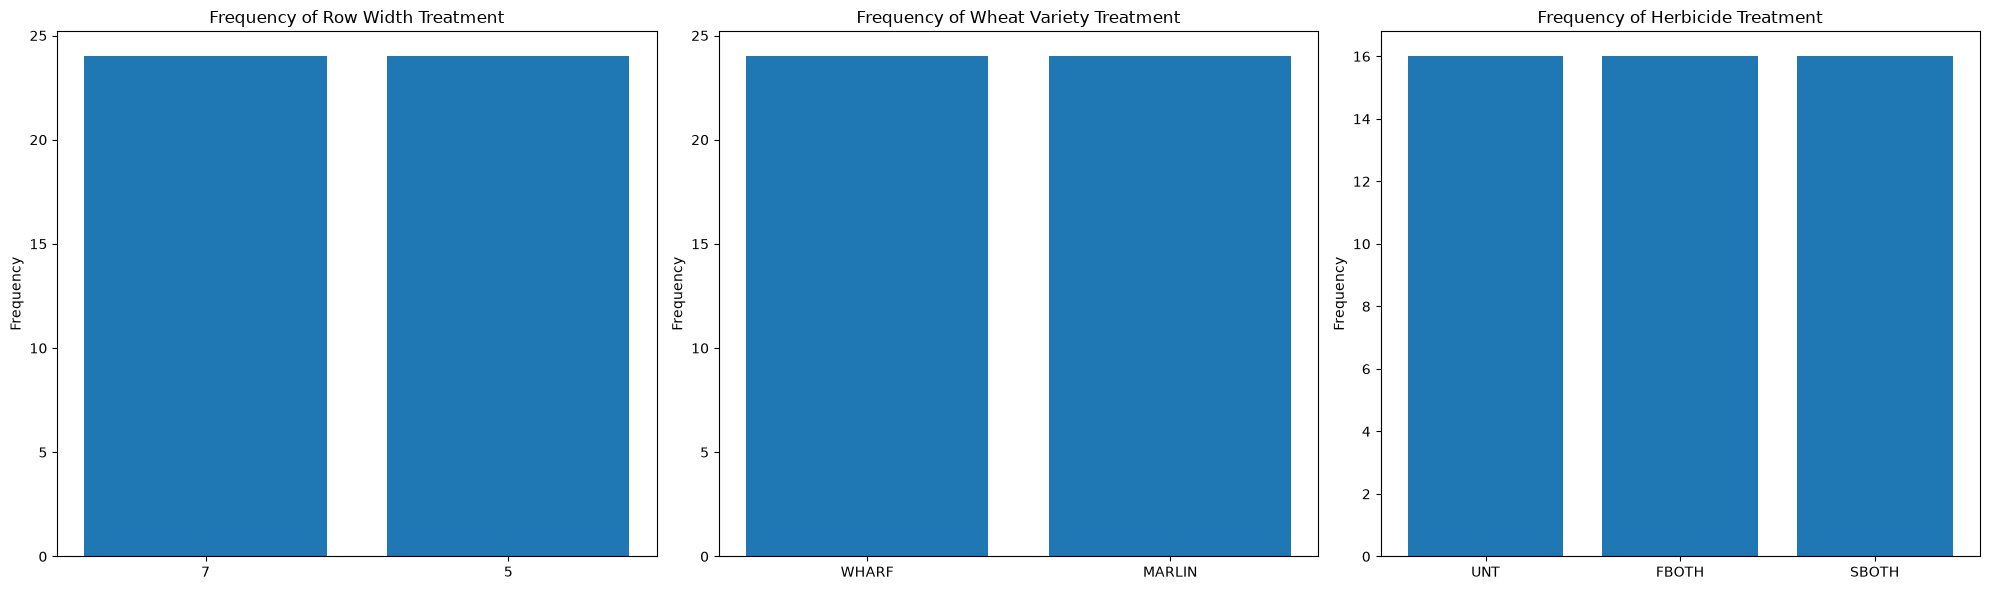

In [7]:
# we expect only 2 row width types, 2 wheat variety types, and 2 herbicide treatment types
# so we expect the number of bars to correspond 

fig, ax = plt.subplots(1, 3)
fig.set_size_inches(20, 6)

bar_data = (np.array([str(x) for x in w_data["WIDTH"].value_counts().index]), w_data["VAR"].value_counts().index, w_data["HERB"].value_counts().index)
bar_values = (w_data["WIDTH"].value_counts().values, w_data["VAR"].value_counts().values, w_data["HERB"].value_counts().values)
bar_titles = ("Frequency of Row Width Treatment", "Frequency of Wheat Variety Treatment", "Frequency of Herbicide Treatment")

for i in range(len(ax)):
    ax[i].bar(bar_data[i], bar_values[i])
    ax[i].set_ylabel("Frequency")
    ax[i].set_title(bar_titles[i])

plt.tight_layout()
plt.savefig("python_figures/categorical_variables_plot.png")

In [28]:
(w_data_width7["WIDTH"].value_counts().index, w_data_width7["WIDTH"].value_counts().values)

(Index([7], dtype='int64', name='WIDTH'), array([24]))

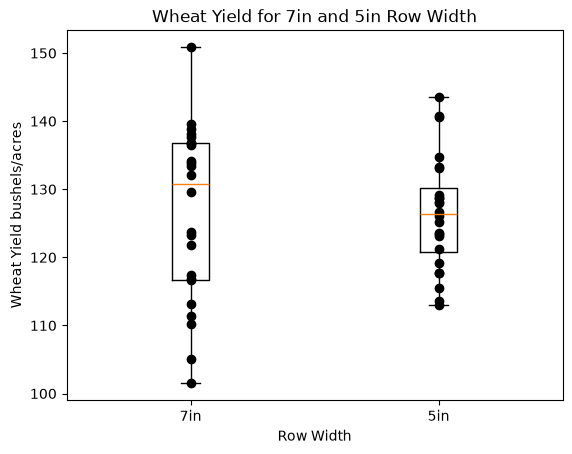

In [8]:
plt.boxplot((yield_data_7, yield_data_5), tick_labels=("7in", "5in"))
plt.title("Wheat Yield for 7in and 5in Row Width")
plt.xlabel("Row Width")
plt.ylabel("Wheat Yield bushels/acres")

for y in yield_data_7:
    plt.scatter(1, y, color="black")

for y in yield_data_5:
    plt.scatter(2, y, color="black")

plt.savefig("python_figures/wheat_yield_boxplot.png")
plt.show()


## Exploratory analysis
### Normality checks (Q-Q plots)

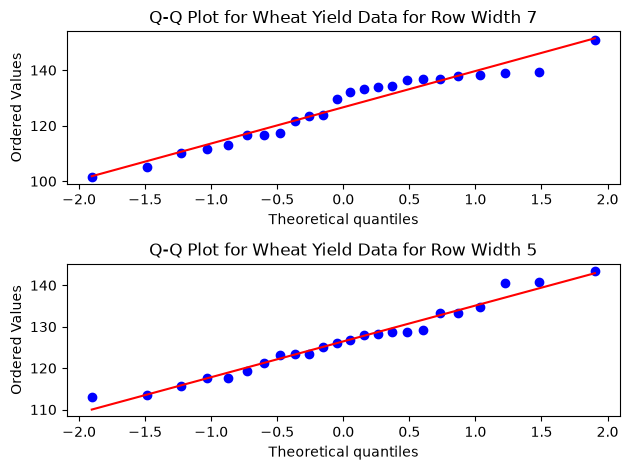

In [9]:
# https://stackoverflow.com/questions/13865596/quantile-quantile-plot-using-scipy
from scipy import stats
fig, ax = plt.subplots(2, 1)
stats.probplot(yield_data_7, dist="norm", plot=ax[0])
ax[0].set_title("Q-Q Plot for Wheat Yield Data for Row Width 7")
stats.probplot(yield_data_5, dist="norm", plot=ax[1])
ax[1].set_title("Q-Q Plot for Wheat Yield Data for Row Width 5")
plt.tight_layout()
plt.savefig("python_figures/Q-Q_Plots_for_row_width_variables.png")

Nothing unusual, dots lay pretty much on the line
### Normality checks (Histograms)

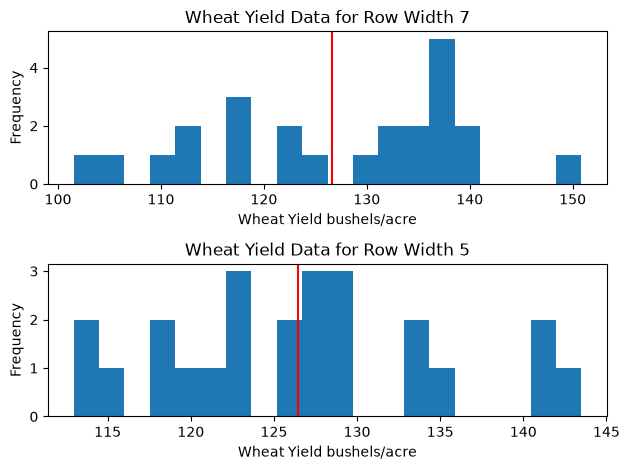

In [10]:
fig, ax = plt.subplots(2, 1)
ax[0].set_title("Wheat Yield Data for Row Width 7")
ax[0].set_xlabel("Wheat Yield bushels/acre")
ax[0].set_ylabel("Frequency")
ax[0].hist(yield_data_7, bins=20)
ax[1].set_title("Wheat Yield Data for Row Width 5")
ax[1].set_xlabel("Wheat Yield bushels/acre")
ax[1].set_ylabel("Frequency")
ax[1].hist(yield_data_5, bins=20)


ax[0].axvline(np.mean(yield_data_7), color="red")
ax[1].axvline(np.mean(yield_data_5), color="red")
plt.tight_layout()
plt.savefig("python_figures/wheat_yield_histogram_for_row_width.png")

Nothing unusual, no apparent outliers or obvious skew

In [11]:
print(descriptive_statistics(yield_data_7))
print(descriptive_statistics(yield_data_5))

count      24.000000
mean      126.641636
std        12.786728
min       101.507627
Q1        116.737617
Median    130.795874
Q3        136.811696
max       150.856172
IQR        20.074079
Name: YIELD, dtype: float64
count      24.000000
mean      126.454730
std         8.365247
min       112.946574
Q1        120.759276
Median    126.422064
Q3        130.185939
max       143.497894
IQR         9.426663
Name: YIELD, dtype: float64


## Welch's two-sample t-test (unequal variances)

Reference code:<br>
https://psiaims.github.io/CAMIS/python/two_samples_t_test.html#code-1<br>
https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html#scipy.stats.ttest_ind

In [12]:
stats.ttest_ind(yield_data_5, yield_data_7, equal_var=False, alternative="two-sided")

TtestResult(statistic=np.float64(-0.059924818179896554), pvalue=np.float64(0.9525166165942027), df=np.float64(39.639711808726105))

In [13]:
stats.ttest_ind(yield_data_5, yield_data_7, equal_var=False, alternative="two-sided").confidence_interval(0.95)

ConfidenceInterval(low=np.float64(-6.492451401085286), high=np.float64(6.118638859418563))

Everything important:

p-value is ~0.95>0.05<br>
confidence interval contains 0 as a plausible value

reference code:

https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html#scipy.stats.permutation_test

In [48]:
stats.permutation_test()

TypeError: permutation_test() missing 2 required positional arguments: 'data' and 'statistic'